## **Exchange Rate pre-processing**

This jupyter notebook is used to pre-process data on exchange rates.

Following part is relevant to both CZK/EUR and CZK/USD codes.

In [1]:
# Importing packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
import json
import os

In [2]:
def params_to_json(prefix, mean, variance):
    """Adds descriptive statistics to json file"""
    json_path = "/Users/jachymsvejda/Documents/GitHub/FIRE_Rule_from_a_Perspective_of_a_Czech_Retail_Investor/data/relationships/statistics.json"
    params={}
    if os.path.exists(json_path):
        try:
            with open(json_path, "r") as f:
                params = json.load(f)
        except json.JSONDecodeError:
                pass
    params[f"{prefix}_mean"] = mean
    params[f"{prefix}_variance"] = variance
    with open(json_path, "w") as f:
        json.dump(params, f)

### **EUR/CZK**

In [3]:
# Data load
eur_czk = pd.read_excel("/Users/jachymsvejda/Documents/GitHub/FIRE_Rule_from_a_Perspective_of_a_Czech_Retail_Investor/data/exchange_rates/EUR_CZK_old.xlsx")

In [4]:
# Get rid of first row
eur_czk.drop(index=eur_czk.index[0], axis=0, inplace=True)

In [5]:
# Data in ascending order by year
eur_czk = eur_czk.sort_values(by="Date").reset_index().drop("index", axis=1)

In [6]:
# Add "Year" column
eur_czk['Year'] = pd.DatetimeIndex(eur_czk['Date']).year

In [7]:
# Fill the column Returns will yearly returns in percentages
eur_czk["Returns"] = np.nan
for i in range(1,len(eur_czk)):
    eur_czk.loc[i, "Returns"] = np.round((eur_czk.loc[i, "EURCZK= (BID)"] - eur_czk.loc[i-1, "EURCZK= (BID)"]) / np.abs(eur_czk.loc[i-1, "EURCZK= (BID)"]), 4)

In [8]:
# Check for Outliers
# Calculate mean, std
eur_std = np.std(eur_czk["Returns"])
eur_mean = np.mean(eur_czk["Returns"])

# Calculate Z-Score
eur_czk["Z-Score"] = np.nan
for i in range(len(eur_czk)):
    eur_czk.loc[i, "Z-Score"] = ((eur_czk.loc[i, "Returns"] - eur_mean) / eur_std)

# Print out Outliers
eur_czk[np.abs(eur_czk["Z-Score"])>3] # Empty hence no outliers

,Date,EURCZK= (BID),Year,Returns,Z-Score


In [9]:
# Export back to Excel
eur_czk.to_excel("/Users/jachymsvejda/Documents/GitHub/FIRE_Rule_from_a_Perspective_of_a_Czech_Retail_Investor/data/exchange_rates/EUR_CZK.xlsx")

In [10]:
# Calculate mean and standard deviation of EUR/CZK Returns
EUR_mean = np.mean(eur_czk["Returns"])
EUR_var = np.var(eur_czk["Returns"])
print(f"The average is {EUR_mean} and the variance is {EUR_var}")

The average is -0.013096153846153848 and the variance is 0.0013832642159763316


In [11]:
# Save mean and variance
params_to_json("EUR", EUR_mean, EUR_var)

<function matplotlib.pyplot.show(close=None, block=None)>

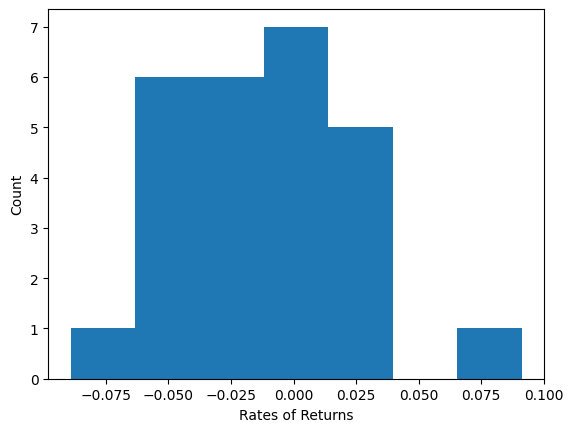

In [11]:
# Create histogram of EUR/CZK Returns
plt.hist(eur_czk["Returns"], bins=7)
plt.xlabel("Rates of Returns")
plt.ylabel("Count")
plt.show
#plt.savefig("/Users/jachymsvejda/Documents/GitHub/FIRE_Rule_from_a_Perspective_of_a_Czech_Retail_Investor/Visualizations/Exchange rate/EUR_hist.pdf", format="pdf", bbox_inches="tight")

### **USD/CZK**

In [12]:
# Data Load
usd_czk = pd.read_excel("/Users/jachymsvejda/Documents/GitHub/FIRE_Rule_from_a_Perspective_of_a_Czech_Retail_Investor/data/exchange_rates/USD_CZK_old.xlsx")

In [13]:
# Transfer column Date to have date format and restrict the data to display only Czech koruna
usd_czk['Date'] = pd.to_datetime(usd_czk['Date'])
usd_czk = usd_czk[usd_czk['Date'] >= '1993-01-01']

# Add "Year" column
usd_czk['Year'] = pd.DatetimeIndex(usd_czk['Date']).year

In [14]:
# Data in ascending order by year
usd_czk = usd_czk.sort_values(by="Date").reset_index().drop("index", axis=1)

In [15]:
# Fill the column Returns will yearly returns in percentages
usd_czk["Returns"] = np.nan
for i in range(1,len(usd_czk)):
    usd_czk.loc[i, "Returns"] = np.round((usd_czk.loc[i, "CZK= (BID)"] - usd_czk.loc[i-1, "CZK= (BID)"]) / np.abs(usd_czk.loc[i-1, "CZK= (BID)"]), 4)

In [16]:
# Check for Outliers
# Calculate mean, std
usd_std = np.std(usd_czk["Returns"])
usd_mean = np.mean(usd_czk["Returns"])

# Calculate Z-Score
usd_czk["Z-Score"] = np.nan
for i in range(len(usd_czk)):
    usd_czk.loc[i, "Z-Score"] = ((usd_czk.loc[i, "Returns"] - usd_mean) / usd_std)

# Print out Outliers
usd_czk[np.abs(usd_czk["Z-Score"])>3] # Empty hence no outliers

,Date,CZK= (BID),Year,Returns,Z-Score


In [17]:
# Export back to Excel
usd_czk.to_excel("/Users/jachymsvejda/Documents/GitHub/FIRE_Rule_from_a_Perspective_of_a_Czech_Retail_Investor/data/exchange_rates/USD_CZK.xlsx")

In [18]:
# Calculate mean and standard deviation of USD/CZK Returns
USD_mean = np.mean(usd_czk["Returns"])
USD_var = np.var(usd_czk["Returns"])
print(f"The average is {USD_mean} and the variance is {USD_var}")

The average is -0.0017437499999999994 and the variance is 0.010628649960937502


In [19]:
# Save mean and variance
params_to_json("USD", USD_mean, USD_var)

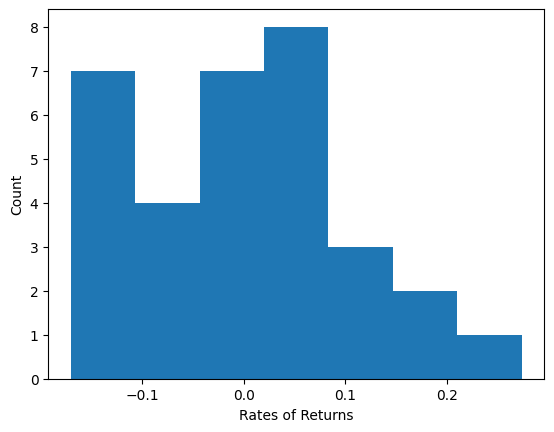

In [67]:
# Create histogram of USD/CZK Returns
plt.hist(usd_czk["Returns"], bins=7)
plt.xlabel("Rates of Returns")
plt.ylabel("Count")
plt.show
plt.savefig("/Users/jachymsvejda/Documents/GitHub/FIRE_Rule_from_a_Perspective_of_a_Czech_Retail_Investor/Visualizations/Exchange rate/USD_hist.pdf", format="pdf", bbox_inches="tight")